# Full Parameter Fine Tuning (FPFT) GPT-2 on MedText

This notebook documents how GPT-2 is fine-tuned to answer questions from the MedText dataset. The workflow covers data preparation, tokenization, baseline evaluation, hyperparameter search, loss visualization, and a qualitative comparison of generated answers.

**Validation loss** measures how well the model predicts the tokens in the reference answers. The final comparison of generated answers is qualitative; neither result alone establishes clinical accuracy.

## 1. Dataset preparation

The `prepare_dataset()` function in `src/dataset_preparation.py` processes the `BI55/MedText` dataset:

1. It resolves the current dataset revision and loads the `Prompt` and `Completion` fields.
2. It strips surrounding whitespace, removes empty examples and duplicate prompts, and renames the fields to `prompt` and `completion`.
3. It splits the examples into **training (80%)**, **validation (10%)**, and **test (10%)** sets using seed `42`.
4. It saves the three splits to `data/processed/medtext_v1` so they can be reused in later runs.

This step cleans and splits the data. **Data augmentation is not implemented** in the current version.

In [1]:
from src.dataset_preparation import prepare_dataset

prepare_dataset()

/home/hpc3/Documents/Projects/medllm-finetuning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data/processed/medtext_v1 already exists


### Load the dataset splits

The notebook loads the processed dataset. In this run, it contains **1,129 training examples**, **141 validation examples**, and **142 test examples**. The training set is used to update model weights; the validation set is used to compare trials and select a checkpoint; the test set is reserved for an independent final evaluation.

If the processed directory already exists, `prepare_dataset()` does not recreate it.

In [16]:
from src.dataset_preparation import load_medtext

train_data, val_data, test_data = load_medtext()

## 2. Tokenization and batch creation

`src/tokenizer.py` uses the `gpt2` encoding from `tiktoken`, which matches the selected model. Each example is formatted as `Question:` followed by the question and `Answer:` followed by the answer. An end-of-text token is appended to the answer.

Question tokens receive the label `-100`. As a result, **the loss is computed only on the answer**, although the model receives both the question and answer as context during training. The `collate_fn` pads each batch to the length of its longest example, builds an `attention_mask`, and assigns `-100` to padding labels.

The notebook creates `DataLoader`s for training, validation, and testing. Training examples are shuffled; validation and test examples retain their order.

In [3]:
import importlib
import src.tokenizer as tokenizer_module

importlib.reload(tokenizer_module)
from src.tokenizer import tokenize_dataset, collate_fn
from torch.utils.data import DataLoader

# [Step 1] First we need to tokenize all data
train_tokenized = tokenize_dataset(train_data)
val_tokenized = tokenize_dataset(val_data)
test_tokenized = tokenize_dataset(test_data)

# [Step 2] Now we need to create the DataLoaders for training, validating and testing

train_loader = DataLoader(
    train_tokenized,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_tokenized,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_tokenized,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
)

## 3. Baseline model and validation loss

The pretrained `openai-community/gpt2` model (about **124 million parameters**) is loaded onto the available device. Before fine-tuning, `evaluate()` computes the average validation loss, weighted by the number of valid answer tokens.

In this run, the **baseline validation loss was 2.8881**. This provides a reference for the grid search results. The optimizer created in this cell is not reused during the grid search: each trial creates its own model and optimizer.

In [4]:
from torch.optim import AdamW
from src.gpt import load_model
from src.evaluation import evaluate

# [Step 1 ] Load the model (in this case gpt2)
# with the pretrained weights from the hugging face
model, device = load_model("openai-community/gpt2")

# [Step 2] Create the optimizer
optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)

# [Step 3] evaluate the model before the Fine tuning
baseline_loss = evaluate(model, val_loader, device)
print(f"Baseline validation loss: {baseline_loss:.4f}")

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 27882.90it/s]
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Device: cuda
Parameters: 124,439,808
Baseline validation loss: 2.8881


## 4. Fine-tuning and hyperparameter search

`run_grid_search()` evaluates **2 batch sizes** (`2` and `8`) × **3 learning rates** (`1e-5`, `2e-5`, and `5e-5`): six trials with five epochs each. Every trial starts from a fresh pretrained GPT-2 model, uses `AdamW` with `weight_decay=0.01`, and clips the gradient norm to `1.0`.

Training and validation losses are recorded after each epoch. Whenever validation loss improves on the best value across all trials, the model is saved to `checkpoints/gpt2-medtext-best`. Trial results are written to `experiments/hpo_results.json`.

| Trial | Batch size | Learning rate | Best validation loss | Epoch |
| ---: | ---: | ---: | ---: | ---: |
| 1 | 2 | `1e-5` | 2.1202 | 5 |
| 2 | 2 | `2e-5` | 2.0859 | 5 |
| **3** | **2** | **`5e-5`** | **2.0832** | **3** |
| 4 | 8 | `1e-5` | 2.1695 | 5 |
| 5 | 8 | `2e-5` | 2.1191 | 5 |
| 6 | 8 | `5e-5` | 2.0881 | 4 |

In this run, the best checkpoint came from **trial 3, epoch 3**. The difference from trial 2 is small (2.0832 versus 2.0859), so this single search does not establish that `5e-5` will consistently perform better.

In [5]:
from src.train import run_grid_search

best, results = run_grid_search(
    train_tokenized,
    val_tokenized,
    collate_fn,
    device,
)


Trial 1/6
Parameters: {'batch_size': 2, 'learning_rate': 1e-05}


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 16692.85it/s]


Epoch 1/5 | Train Loss: 2.5609 | Val Loss: 2.2655


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.67it/s]


Epoch 2/5 | Train Loss: 2.2934 | Val Loss: 2.1976


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.17it/s]


... (21 outputs left out)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 21951.94it/s]


Epoch 1/5 | Train Loss: 2.5677 | Val Loss: 2.2672
Epoch 2/5 | Train Loss: 2.2873 | Val Loss: 2.1915
Epoch 3/5 | Train Loss: 2.1508 | Val Loss: 2.1605
Epoch 4/5 | Train Loss: 2.0502 | Val Loss: 2.1348
Epoch 5/5 | Train Loss: 1.9622 | Val Loss: 2.1191

Trial 6/6
Parameters: {'batch_size': 8, 'learning_rate': 5e-05}


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 19138.49it/s]


Epoch 1/5 | Train Loss: 2.4804 | Val Loss: 2.1982
Epoch 2/5 | Train Loss: 2.1083 | Val Loss: 2.1266
Epoch 3/5 | Train Loss: 1.9019 | Val Loss: 2.0997
Epoch 4/5 | Train Loss: 1.7403 | Val Loss: 2.0881
Epoch 5/5 | Train Loss: 1.5915 | Val Loss: 2.0974

Best hyperparameters:
{'trial': 3, 'batch_size': 2, 'learning_rate': 5e-05, 'best_val_loss': 2.0831837855470834, 'best_epoch': 3, 'train_losses': [2.443897282379801, 1.9514470572725002, 1.658772141427354, 1.416677765124341, 1.2076875643462426], 'val_losses': [2.1602738406839936, 2.0899903512251132, 2.0831837855470834, 2.1004600731182563, 2.195061475100068]}


## 5. Loss visualization

The plot compares the **training** and **validation** curves for all six trials. Its third panel compares the best validation loss for each hyperparameter combination. The horizontal line in the validation panel marks the original GPT-2 validation loss (`baseline_loss`). The figure is also saved to `experiments/grid_search_losses.png`.

In trial 3, validation loss falls to **2.0832 at epoch 3** and then rises in epochs 4 and 5, while training loss keeps falling. This suggests overfitting after epoch 3. The checkpoint saved at the best epoch is therefore more relevant than the model at the end of that trial.

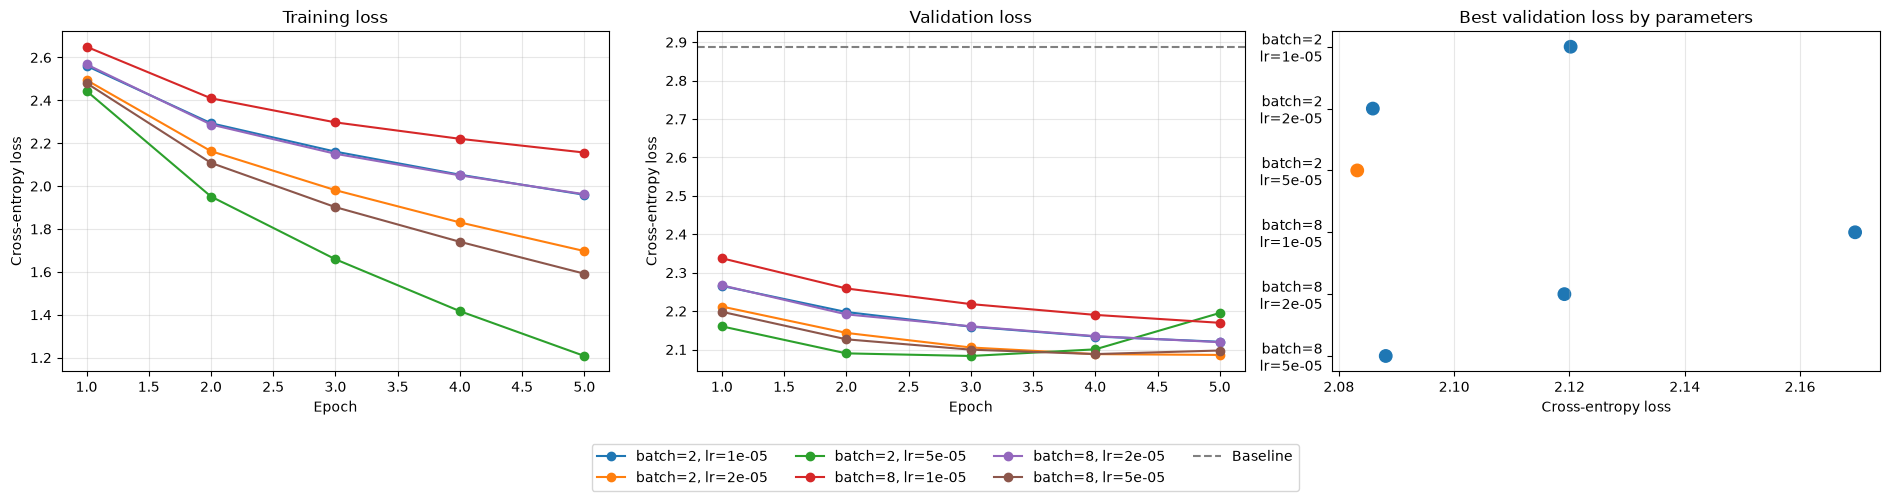

In [7]:
import importlib
import src.plot as plot_module

importlib.reload(plot_module)

plot_module.plot_grid_search(
    results,
    baseline_val_loss=baseline_loss,
)

## 6. Qualitative comparison of generated answers

The next cell loads the original GPT-2 model and the checkpoint with the best validation loss. For the **first ten questions in the validation split**, it displays the question, the reference answer, and both models' answers. Both models receive the same `Question:`/`Answer:` prompt format and generate up to 100 new tokens with deterministic decoding (`do_sample=False`).

Reviewing these outputs can reveal repetition, incoherence, or disagreement with the reference. In this run, for example, the fine-tuned model identifies the topic of the first case, but its answer to the second case differs from the reference. **These ten examples do not measure clinical accuracy.** They also come from the validation split, which was already used to select the checkpoint.

In [15]:
from src.inference import generate_response
from transformers import AutoModelForCausalLM
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
base_model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device)

finetuned_model = AutoModelForCausalLM.from_pretrained(
    "checkpoints/gpt2-medtext-best"
).to(device)

for i in range(10):
    question = val_data[i]["prompt"]
    reference = val_data[i]["completion"]

    base_response = generate_response(
        base_model, question, device, tokenizer
    )

    ft_response = generate_response(
        finetuned_model, question, device, tokenizer
    )

    print(f"\nQUESTION:\n{question}")
    print(f"\nREFERENCE:\n{reference}")
    print(f"\nBASE MODEL:\n{base_response}")
    print(f"\nFINE-TUNED:\n{ft_response}")
    print("-" * 80)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 24547.49it/s]



QUESTION:
A knee X-ray of a 60-year-old female patient with chronic knee pain shows joint space narrowing and bony spurs around the joint. What is the most likely diagnosis?

REFERENCE:
These findings are characteristic of osteoarthritis, a degenerative joint disease that frequently affects weight-bearing joints like the knees. It is characterized by the breakdown of cartilage, leading to bone remodeling, joint space narrowing, and osteophyte (bony spur) formation. Management is usually conservative initially, with lifestyle modifications, physiotherapy, and analgesics. Surgical options like joint replacement may be considered in severe cases.

BASE MODEL:
The patient's condition is not known.

The patient's condition is not known.

The patient's condition is not known.

The patient's condition is not known.

The patient's condition is not known.

The patient's condition is not known.

The patient's condition is not known.

The patient's condition is not known.

The patient's conditio

## Current status

The data preparation, fine-tuning, validation-loss-based checkpoint selection, and qualitative comparison have been run. The best recorded **validation loss is 2.0832**, compared with **2.8881 before fine-tuning**. The test split has been created and loaded, but **the selected checkpoint has not yet been evaluated on it**.

The next step is to evaluate the checkpoint on the test split and review its answers against explicit criteria for correctness and safety, especially because the content is medical.

In [18]:
import math
import torch

from transformers import AutoModelForCausalLM
from src.evaluation import evaluate

# Original GPT-2
base_model = AutoModelForCausalLM.from_pretrained(
    "openai-community/gpt2"
).to(device)

# Best fine-tuned GPT-2
finetuned_model = AutoModelForCausalLM.from_pretrained(
    "checkpoints/gpt2-medtext-best"
).to(device)

# Evaluate both models
base_test_loss = evaluate(
    base_model, test_loader, device
)

finetuned_test_loss = evaluate(
    finetuned_model, test_loader, device
)

# Calculate perplexity
base_ppl = math.exp(base_test_loss)
finetuned_ppl = math.exp(finetuned_test_loss)

print("\n--- TEST RESULTS ---")

print(f"Base GPT-2 Test Loss: {base_test_loss:.4f}")
print(f"Fine-tuned Test Loss: {finetuned_test_loss:.4f}")

print(f"Base GPT-2 Perplexity: {base_ppl:.4f}")
print(f"Fine-tuned Perplexity: {finetuned_ppl:.4f}")

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 21669.18it/s]



--- TEST RESULTS ---
Base GPT-2 Test Loss: 2.9026
Fine-tuned Test Loss: 2.0649
Base GPT-2 Perplexity: 18.2221
Fine-tuned Perplexity: 7.8847
